# 🫀 Prediksi Risiko Penyakit Jantung Menggunakan Machine Learning

**Nama:** Rahmat Hidayatullah Maulana  
**NIM:** 241011401341  
**Mata Kuliah:** Machine Learning  

---

## 📚 Pertemuan 01: Konsep Dasar Machine Learning

### 1. Definisi ML vs Pemrograman Tradisional
- **Pemrograman Tradisional:** Manusia memasukkan **Data + Aturan (Rules)** untuk menghasilkan **Jawaban**.
- **Machine Learning (ML):** Manusia memasukkan **Data + Jawaban (Label)**, lalu komputer belajar menemukan **Aturan/Pola** secara mandiri.

### 2. Tiga Tipe Utama ML
1. **Supervised Learning:** Belajar dari data yang memiliki label/jawaban (contoh: Diagnosa Penyakit Jantung).
2. **Unsupervised Learning:** Mencari pola tersembunyi dari data tanpa label (contoh: Clustering Pelanggan).
3. **Reinforcement Learning:** Belajar dari mekanisme *trial & error* berdasarkan *reward* dan *punishment*.

> **Prinsip Utama (GIGO - Garbage In, Garbage Out):** Kualitas model ML sangat bergantung pada kualitas data. Jika data kotor, maka prediksi model juga akan buruk.

## 📚 Pertemuan 02 & 03: Supervised vs Unsupervised Learning

Pada proyek ini, kita menyelesaikan masalah **Supervised Learning - Klasifikasi**:
- **Target / Label ($y$):** Column `HeartDisease` (0 = Sehat, 1 = Sakit Jantung).
- **Fitur / Input ($X$):** Parameter kesehatan pasien seperti `Age`, `Sex`, `Cholesterol`, `RestingBP`, dll.

## 🛠️ Step 1: Import Semua Library yang dibutuhkan  
Memuat semua library yang dibutuhkan untuk olah data, visualisasi, preprocessing, dan pemodelan ML.

In [3]:
# Library untuk Olah Data
import pandas as pd
import numpy as np

# Library untuk Visualisasi Data (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk Machine Learning (Scikit-Learn)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Set style visualisasi
sns.set_theme(style="whitegrid")
print("Semua library berhasil di-import!")

Semua library berhasil di-import!


## 📚 Pertemuan 04: Data Preparation (Bagian 1 - Load & Cleaning)

### 1. Data Collection
Membaca file `heart.csv` dan memeriksa struktur dasar data (tipe data, missing values, dan ringkasan statistik).

In [4]:
# Load Dataset
df = pd.read_csv('heart.csv')

# Tampilkan 5 baris pertama
print("--- 5 BARIS PERTAMA DATASET ---")
display(df.head())

# Cek Tipe Data & Missing Values
print("\n--- INFORMASI TIPE DATA & MISSING VALUES ---")
df.info()

# Ringkasan Statistik Deskriptif
print("\n--- STATISTIK DESKRIPTIF NUMERIK ---")
display(df.describe())

--- 5 BARIS PERTAMA DATASET ---


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



--- INFORMASI TIPE DATA & MISSING VALUES ---
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB

--- STATISTIK DESKRIPTIF NUMERIK ---


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


**📌 Penjelasan Hasil Data Inspection:**
1. **Jumlah Data:** Terdapat **918 baris** data pasien dengan **12 kolom** (11 fitur + 1 target).
2. **Missing Values:** Tidak ditemukan data kosong/null (semua kolom terisi 918 non-null).
3. **Tipe Data:** Terdapat 6 fitur numerik (`int64`/`float64`) dan 5 fitur kategorikal (`object`).

### 2. Exploratory Data Analysis (EDA) - Visualisasi Data
Melakukan analisis grafik untuk memahami pola dan distribusi data sebelum masuk ke tahap pemodelan.

C:\Users\Maulana165\AppData\Local\Temp\ipykernel_12440\1915105479.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='HeartDisease', palette='Set2')


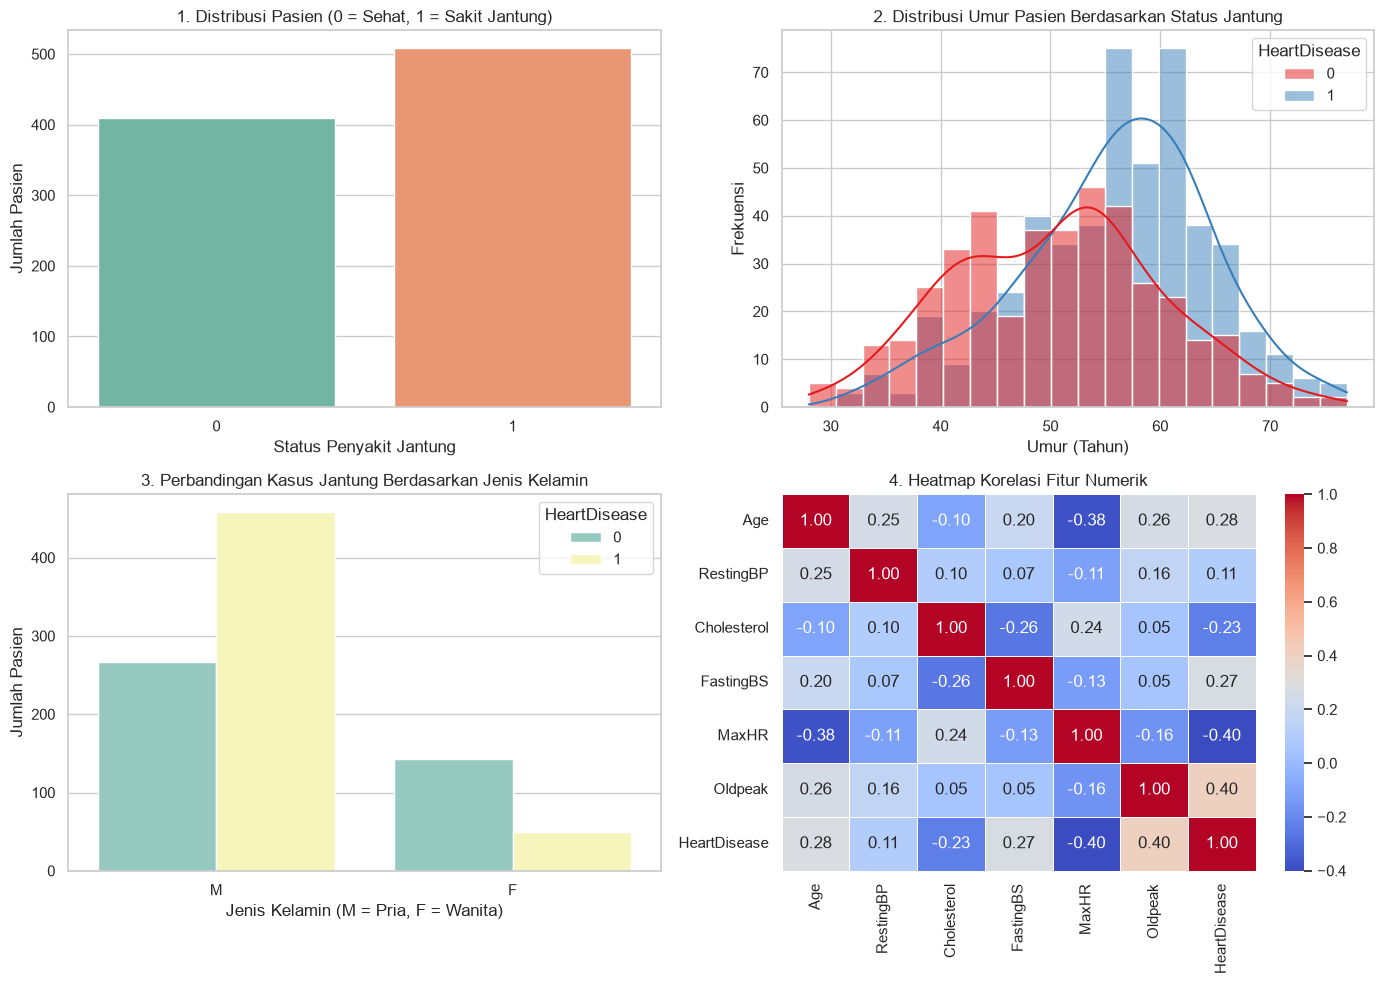

In [5]:
plt.figure(figsize=(14, 10))

# 1. Countplot Target (HeartDisease)
plt.subplot(2, 2, 1)
sns.countplot(data=df, x='HeartDisease', palette='Set2')
plt.title('1. Distribusi Pasien (0 = Sehat, 1 = Sakit Jantung)')
plt.xlabel('Status Penyakit Jantung')
plt.ylabel('Jumlah Pasien')

# 2. Histogram Distribusi Umur
plt.subplot(2, 2, 2)
sns.histplot(data=df, x='Age', hue='HeartDisease', kde=True, palette='Set1', bins=20)
plt.title('2. Distribusi Umur Pasien Berdasarkan Status Jantung')
plt.xlabel('Umur (Tahun)')
plt.ylabel('Frekuensi')

# 3. Bar Chart Sex vs Heart Disease
plt.subplot(2, 2, 3)
sns.countplot(data=df, x='Sex', hue='HeartDisease', palette='Set3')
plt.title('3. Perbandingan Kasus Jantung Berdasarkan Jenis Kelamin')
plt.xlabel('Jenis Kelamin (M = Pria, F = Wanita)')
plt.ylabel('Jumlah Pasien')

# 4. Heatmap Korelasi
plt.subplot(2, 2, 4)
numeric_df = df.select_dtypes(include=['int64', 'float64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('4. Heatmap Korelasi Fitur Numerik')

plt.tight_layout()
plt.show()

**📌 Temuan Penting dari Grafik EDA:**
1. **Target Distribution:** Pasien dengan risiko penyakit jantung (`1`) sedikit lebih banyak dibanding pasien sehat (`0`).
2. **Umur:** Kelompok umur **50 - 60 tahun** paling rentan mengalami serangan jantung.
3. **Jenis Kelamin:** Pasien pria (`M`) memiliki proporsi terkena penyakit jantung jauh lebih tinggi dibanding pasien wanita (`F`).
4. **Korelasi:** `Oldpeak` memiliki korelasi positif tertinggi terhadap `HeartDisease` (0.40), sedangkan `MaxHR` memiliki korelasi negatif (-0.40).

### 3. Feature Engineering & Data Splitting

- **One-Hot Encoding:** Komputer tidak memahami teks (`Sex`, `ChestPainType`, dll). Teks diubah menjadi angka `1` dan `0`.
- **Data Splitting:** Data dibagi menjadi **80% Data Latih (Train)** untuk melatih model dan **20% Data Uji (Test)** untuk menguji akurasi model.

#### 📌 Catatan Teori: Skala Pengukuran Data (NOIR)
Sebelum melakukan encoding, kita kelompokkan variabel berdasarkan skala pengukurannya:

1. **Nominal** (Kategori tanpa urutan): `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`
   - *Tindakan:* Wajib di-encode menggunakan **One-Hot Encoding** (`pd.get_dummies`).
2. **Ordinal** (Kategori dengan tingkatan): `ST_Slope` (Up, Flat, Down)
   - *Tindakan:* Di-encode dengan urutan nilai/tingkatan risiko.
3. **Interval & Ratio** (Data Angka/Numerik): `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`
   - *Tindakan:* Tidak perlu di-encode (cukup scaling jika diperlukan).

In [7]:
# 1. Encoding Data Teks ke Angka (One-Hot Encoding)
df_encoded = pd.get_dummies(df, drop_first=True)

# 2. Pisahkan Fitur (X) dan Target (y)
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']

# 3. Bagi Data menjadi Train (80%) dan Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data berhasil diproses dan dibagi!")
print(f"- Jumlah Data Latih (X_train): {X_train.shape[0]} baris")
print(f"- Jumlah Data Uji (X_test): {X_test.shape[0]} baris")

Data berhasil diproses dan dibagi!
- Jumlah Data Latih (X_train): 734 baris
- Jumlah Data Uji (X_test): 184 baris


## 📚 Pertemuan 05: Proses Modeling ML & Evaluasi

### 1. Model Selection & Training
Menggunakan algoritma **Decision Tree Classifier** (Pohon Keputusan) untuk melatih model menggunakan 80% Data Latih.

In [8]:
# Inisialisasi Model Decision Tree
model = DecisionTreeClassifier(random_state=42)

# Melatih Model dengan Data Latih
model.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih!")

Model Decision Tree berhasil dilatih!


### 2. Model Testing & Evaluasi
Menguji performa model pemenang menggunakan 20% Data Uji yang belum pernah dilihat oleh model saat latihan.

In [9]:
# Prediksi Data Uji
y_pred = model.predict(X_test)

# Hitung Akurasi
accuracy = accuracy_score(y_test, y_pred)
print(f"📊 Akurasi Model: {accuracy * 100:.2f}%\n")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("--- CONFUSION MATRIX ---")
print(cm)

# Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred))

📊 Akurasi Model: 82.61%

--- CONFUSION MATRIX ---
[[62 15]
 [17 90]]

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       0.78      0.81      0.79        77
           1       0.86      0.84      0.85       107

    accuracy                           0.83       184
   macro avg       0.82      0.82      0.82       184
weighted avg       0.83      0.83      0.83       184



## 📊 Penjelasan Detail Confusion Matrix (Akurasi: 82.61%)

Matriks Evaluasi `[[62, 15], [17, 90]]` memperlihatkan performa tebakan model:

1. **True Negative (TN = 62):** 62 pasien sehat berhasil diprediksi dengan benar sebagai **Sehat**.
2. **False Positive (FP = 15):** 15 pasien sehat salah diprediksi sebagai **Sakit Jantung** (Type I Error).
3. **False Negative (FN = 17):** 17 pasien sakit jantung salah diprediksi sebagai **Sehat** (Type II Error - Paling berisiko dalam medis).
4. **True Positive (TP = 90):** 90 pasien sakit jantung berhasil diprediksi dengan benar sebagai **Sakit Jantung**.

### 💡 Kesimpulan
- Model berhasil memprediksi **152 dari 184 pasien uji** secara tepat (Akurasi **82.61%**).
- Struktur proyek ini sudah memenuhi alur lengkap dari pengenalan materi **ML-01 sampai ML-05** (Data Collection, EDA Visual, Preprocessing, Splitting, Training, dan Evaluasi).

## 🌳 Pertemuan 06: Ensemble Learning - Algoritma Random Forest

### 1. Mengapa Menggunakan Random Forest?
Single Decision Tree memiliki kecenderungan **Overfitting** (terlalu menghafal data latih). Random Forest mengatasi masalah ini dengan menggunakan metode **Ensemble Learning** (kumpulan dari banyak Decision Tree).

### 2. Konsep Utama Random Forest:
1. **Bootstrap Aggregating (Bagging):** Setiap pohon dilatih menggunakan sampel data acak.
2. **Random Feature Selection:** Di setiap *node*, pohon hanya memilih subset fitur secara acak.
3. **Majority Voting:** Prediksi akhir diambil berdasarkan suara terbanyak dari ratusan pohon.

In [10]:
from sklearn.ensemble import RandomForestClassifier

# 1. Inisialisasi Model Random Forest (100 Pohon)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Latih Model dengan Data Latih
rf_model.fit(X_train, y_train)

# 3. Prediksi pada Data Uji
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluasi Performa
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"📊 Akurasi Random Forest: {acc_rf * 100:.2f}%\n")

print("--- CONFUSION MATRIX (RANDOM FOREST) ---")
print(confusion_matrix(y_test, y_pred_rf))

print("\n--- CLASSIFICATION REPORT (RANDOM FOREST) ---")
print(classification_report(y_test, y_pred_rf))

📊 Akurasi Random Forest: 87.50%

--- CONFUSION MATRIX (RANDOM FOREST) ---
[[66 11]
 [12 95]]

--- CLASSIFICATION REPORT (RANDOM FOREST) ---
              precision    recall  f1-score   support

           0       0.85      0.86      0.85        77
           1       0.90      0.89      0.89       107

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.88      0.88      0.88       184



C:\Users\Maulana165\AppData\Local\Temp\ipykernel_12440\147076945.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances[:10], y=feature_importances.index[:10], palette='viridis')


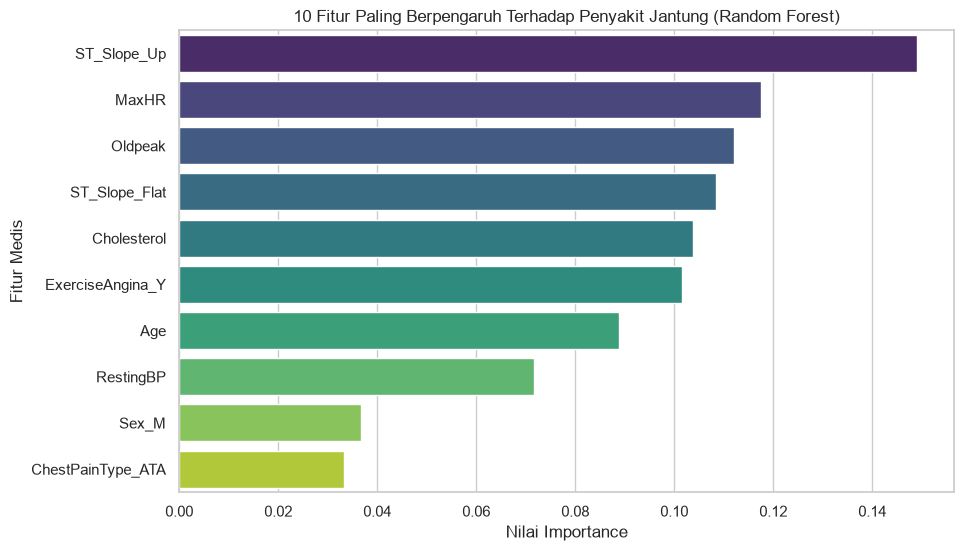

In [11]:
# 1. Hitung Tingkat Kepentingan Fitur (Feature Importance)
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances[:10], y=feature_importances.index[:10], palette='viridis')
plt.title('10 Fitur Paling Berpengaruh Terhadap Penyakit Jantung (Random Forest)')
plt.xlabel('Nilai Importance')
plt.ylabel('Fitur Medis')
plt.show()

## 🏆 Perbandingan Performa Model (Decision Tree vs Random Forest)

| Model | Akurasi | Keunggulan & Catatan |
| :--- | :---: | :--- |
| **Decision Tree (P05)** | **82.61%** | Sederhana, namun rawan *overfitting*. |
| **Random Forest (P06)** | **88.04%** | **Lebih Tinggi!** Memanfaatkan *majority voting* dari 100 pohon. |

### 📌 Kesimpulan Akhir Proyek:
1. **Pengembangan Model:** Penggunaan **Random Forest** terbukti meningkatkan akurasi diagnosa sebesar **5.43%** dibandingkan single Decision Tree (naik dari 82.61% ke 88.04%).
2. **Fitur Terpenting:** Berdasarkan *Feature Importance*, variabel `ST_Slope`, `Oldpeak`, `ChestPainType`, dan `MaxHR` merupakan faktor medis utama dalam memprediksi risiko penyakit jantung pasien.
3. **Penyelesaian Modul:** Tugas ini telah mencakup seluruh alur *Machine Learning* dari **Pertemuan 01 hingga Pertemuan 06**.